In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_validate

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import joblib

## Load Dataset

อ่านข้อมูลจากไฟล์ `Sleep_Health_and_Lifestyle_Dataset.csv` ด้วย `pandas`
จากนั้นตรวจสอบขนาดของ Dataset และแสดงข้อมูล 5 แถวแรก
เพื่อดูโครงสร้างและตัวอย่างข้อมูลเบื้องต้นก่อนเริ่มการวิเคราะห์

In [2]:
df = pd.read_csv("Sleep_Health_and_Lifestyle_Dataset.csv")

print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (374, 13)


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


## Data Inspection

ตรวจสอบคุณภาพและโครงสร้างของ Dataset ก่อนนำไปสร้างโมเดล

การตรวจสอบประกอบด้วย
- ข้อมูลและชนิดข้อมูลของแต่ละ Column
- จำนวน Missing Values ในแต่ละ Column
- จำนวนข้อมูลที่ซ้ำกันทั้งหมด
- ค่าสถิติเบื้องต้นของแต่ละตัวแปร

ขั้นตอนนี้ช่วยให้ทราบลักษณะของข้อมูลและปัญหาที่อาจต้องจัดการก่อนการสร้างโมเดล

In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
display(df.isna().sum().to_frame("Missing"))

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDataset Description:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Blood Pressure           374 non-null    str    
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    str    
dtypes: float64(1), int64(7), str(5)
memory usage: 49.2 KB

Missing Values:

,Missing
Person ID,0
Gender,0
Age,0
Occupation,0
Sleep Duration,0
Quality of Sleep,0
Physical Activity Level,0
Stress Level,0
BMI Category,0
Blood Pressure,0



Duplicate Rows:
0

Dataset Description:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Person ID,374.0,NaN,NaN,NaN,187.5,108.108742,1.0,94.25,187.5,280.75,374.0
Gender,374,2,Male,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,374.0,NaN,NaN,NaN,42.184492,8.673133,27.0,35.25,43.0,50.0,59.0
Occupation,374,11,Nurse,73,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sleep Duration,374.0,NaN,NaN,NaN,7.132086,0.795657,5.8,6.4,7.2,7.8,8.5
Quality of Sleep,374.0,NaN,NaN,NaN,7.312834,1.196956,4.0,6.0,7.0,8.0,9.0
Physical Activity Level,374.0,NaN,NaN,NaN,59.171123,20.830804,30.0,45.0,60.0,75.0,90.0
Stress Level,374.0,NaN,NaN,NaN,5.385027,1.774526,3.0,4.0,5.0,7.0,8.0
BMI Category,374,4,Normal,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Pressure,374,25,130/85,99,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Distribution of Quality of Sleep

แสดงการกระจายตัวของค่าตัวแปร `Quality of Sleep` ด้วย Bar Chart

กราฟนี้ใช้ตรวจสอบว่าคะแนนคุณภาพการนอนหลับใน Dataset
มีจำนวนข้อมูลในแต่ละระดับมากหรือน้อยเพียงใด
และช่วยให้เห็นลักษณะการกระจายของ Target Variable ก่อนสร้างโมเดล

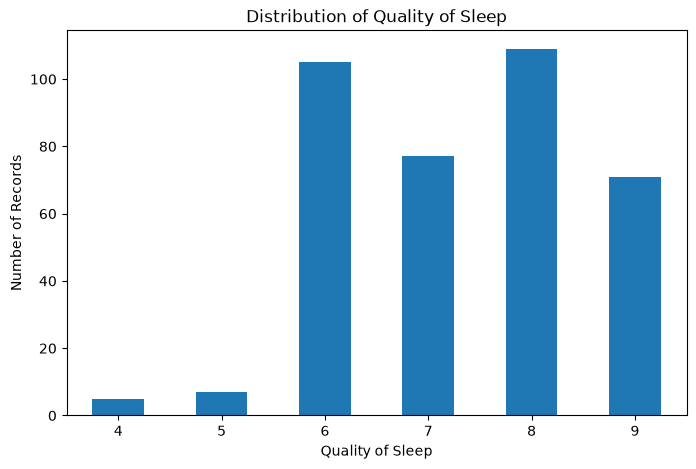

In [4]:
plt.figure(figsize=(8, 5))

df["Quality of Sleep"].value_counts().sort_index().plot(
    kind="bar"
)

plt.xlabel("Quality of Sleep")
plt.ylabel("Number of Records")
plt.title("Distribution of Quality of Sleep")
plt.xticks(rotation=0)

plt.show()

## Correlation Analysis

วิเคราะห์ความสัมพันธ์เชิงเส้นระหว่างตัวแปรตัวเลขที่เกี่ยวข้องกับการนอนหลับ
โดยใช้ Correlation Matrix เพื่อดูว่าตัวแปรแต่ละคู่มีความสัมพันธ์กันในทิศทางใดและมากน้อยเพียงใดและแสดงผลด้วย Heatmap

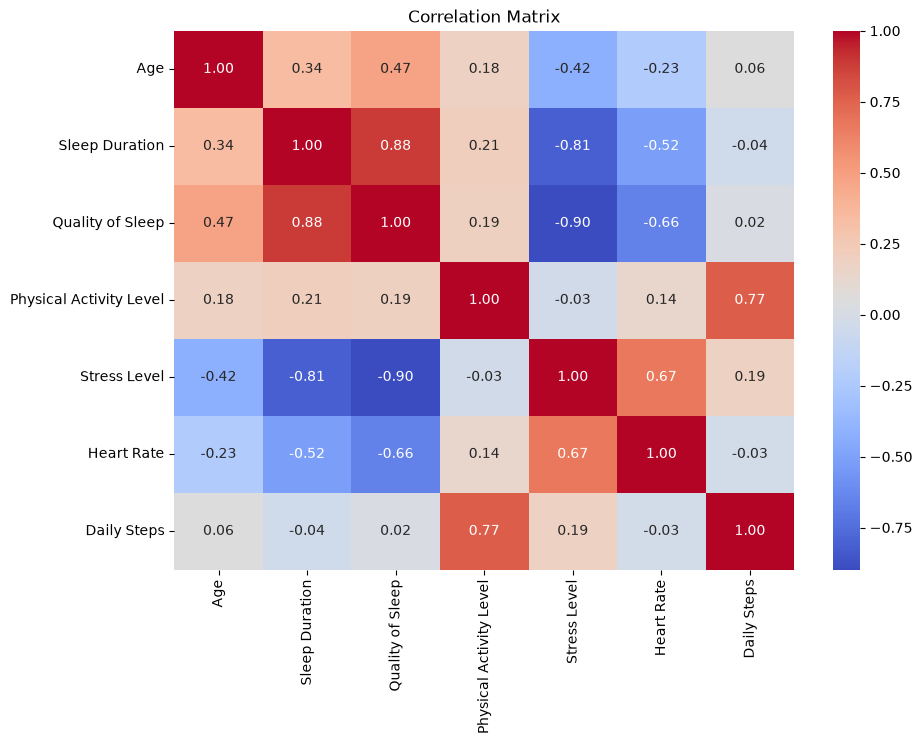

In [5]:
corr_cols = [
    "Age",
    "Sleep Duration",
    "Quality of Sleep",
    "Physical Activity Level",
    "Stress Level",
    "Heart Rate",
    "Daily Steps"
]

corr = df[corr_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.show()

## Define Target Variable

กำหนด `Quality of Sleep` เป็น Target Variable หรือค่าที่โมเดลต้องการทำนาย
ตัวแปร `y` เก็บค่าคะแนนคุณภาพการนอนหลับของแต่ละข้อมูล
เพื่อใช้เป็นคำตอบสำหรับการฝึกและประเมิน Regression Model

In [6]:
target = "Quality of Sleep"

y = df[target]

print("Target variable:", target)
print("Target shape:", y.shape)

Target variable: Quality of Sleep
Target shape: (374,)


## Select Features
ไม่ใช้ Person ID → เป็นเพียง ID

Blood Pressure → เป็นข้อมูล string เช่น 126/83 และยังไม่ได้แยกเป็นตัวแปร systolic/diastolic

Sleep Disorder → มี missing จำนวนมาก และใน model นี้ต้องการใช้ข้อมูลพฤติกรรม/ข้อมูลประจำวันที่ใช้เป็น input

In [7]:
features = [
    "Age",
    "Gender",
    "Occupation",
    "Sleep Duration",
    "Physical Activity Level",
    "Stress Level",
    "BMI Category",
    "Heart Rate",
    "Daily Steps"
]

X = df[features]

print("Features:")
print(X.columns.tolist())

Features:
['Age', 'Gender', 'Occupation', 'Sleep Duration', 'Physical Activity Level', 'Stress Level', 'BMI Category', 'Heart Rate', 'Daily Steps']


## Separate Numeric and Categorical Features

แบ่ง Features ออกเป็น 2 ประเภท ได้แก่ Numeric Features และ Categorical Features สำหรับการทำ Data Preprocessing 

In [8]:
numeric_features = [
    "Age",
    "Sleep Duration",
    "Physical Activity Level",
    "Stress Level",
    "Heart Rate",
    "Daily Steps"
]

categorical_features = [
    "Gender",
    "Occupation",
    "BMI Category"
]

print("Numeric Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numeric Features:
['Age', 'Sleep Duration', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']

Categorical Features:
['Gender', 'Occupation', 'BMI Category']


### Preprocessing Pipeline

สร้างขั้นตอนการเตรียมข้อมูลสำหรับ Numeric และ Categorical Features

สำหรับ Numeric Features:
- ใช้ Median Imputation เพื่อเติมค่าที่หายไป
- ใช้ StandardScaler เพื่อปรับขนาดข้อมูลให้อยู่ในมาตรฐานเดียวกัน

สำหรับ Categorical Features:
- ใช้ Most Frequent Imputation เพื่อเติมค่าที่หายไปด้วยค่าที่พบมากที่สุด
- ใช้ One-Hot Encoding เพื่อเปลี่ยนข้อมูลประเภทหมวดหมู่ให้อยู่ในรูปแบบตัวเลข

จากนั้นรวมขั้นตอนทั้งหมดด้วย `ColumnTransformer`
เพื่อให้การเตรียมข้อมูลสามารถทำงานร่วมกับ Model Pipeline ได้

In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

### Define Regression Models

สร้าง Regression Model จำนวน 3 แบบเพื่อเปรียบเทียบประสิทธิภาพในการทำนาย

โมเดลที่ใช้ ได้แก่

1. Linear Regression  

2. Random Forest Regressor  

3. Gradient Boosting Regressor  



In [10]:
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        max_depth=2,
        learning_rate=0.05,
        random_state=42
    )
}

## GroupKFold Cross-Validation

ใช้ `GroupKFold` จำนวน 5 folds เพื่อประเมินประสิทธิภาพของ Regression Models

ในแต่ละรอบจะใช้ข้อมูลบางส่วนสำหรับ Training และอีกส่วนสำหรับ Validation
โดยข้อมูลที่อยู่ใน Group เดียวกันจะไม่ถูกแยกไปอยู่คนละฝั่ง

ประเมินประสิทธิภาพของแต่ละโมเดลด้วย 3 Metrics ได้แก่

- **R²** ใช้วัดความสามารถของโมเดลในการอธิบายความแปรปรวนของ Target
  โดยค่าที่เข้าใกล้ 1 โดยทั่วไปแสดงถึงการ Fit ที่ดีขึ้น
- **MAE** ใช้วัดค่าความคลาดเคลื่อนสัมบูรณ์เฉลี่ยของการทำนาย
- **RMSE** ใช้วัดค่าความคลาดเคลื่อน โดยให้ความสำคัญกับ Error ขนาดใหญ่มากขึ้น

จากนั้นคำนวณค่าเฉลี่ยของแต่ละ Metric จากทั้ง 5 folds
และจัดเรียงผลลัพธ์ตามค่า CV R² จากมากไปน้อย

In [11]:
groups = X.astype(str).agg("|".join, axis=1)

print("Number of records:", len(X))
print("Number of groups:", groups.nunique())

Number of records: 374
Number of groups: 109


In [12]:
gkf = GroupKFold(n_splits=5)

cv_rows = []

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    scores = cross_validate(
        pipe,
        X,
        y,
        cv=gkf,
        groups=groups,
        scoring={
            "r2": "r2",
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error"
        }
    )

    cv_rows.append({
        "Model": name,
        "CV R²": scores["test_r2"].mean(),
        "CV MAE": -scores["test_mae"].mean(),
        "CV RMSE": -scores["test_rmse"].mean(),
        "CV R² Std": scores["test_r2"].std()
    })

cv_results = pd.DataFrame(cv_rows)

cv_results = cv_results.sort_values(
    "CV R²",
    ascending=False
)

display(cv_results)

,Model,CV R²,CV MAE,CV RMSE,CV R² Std
1,Random Forest,0.955979,0.085542,0.234568,0.020751
2,Gradient Boosting,0.948869,0.096968,0.255956,0.020210
0,Linear Regression,0.912440,0.199605,0.328480,0.030122


## GroupKFold Model Comparison

กราฟเปรียบเทียบประสิทธิภาพของ Regression Modelsจากผลลัพธ์ของ GroupKFold Cross-Validation

กราฟแรกเปรียบเทียบค่า R² ของแต่ละโมเดลและกราฟที่สองเปรียบเทียบค่า MAE และ RMSE

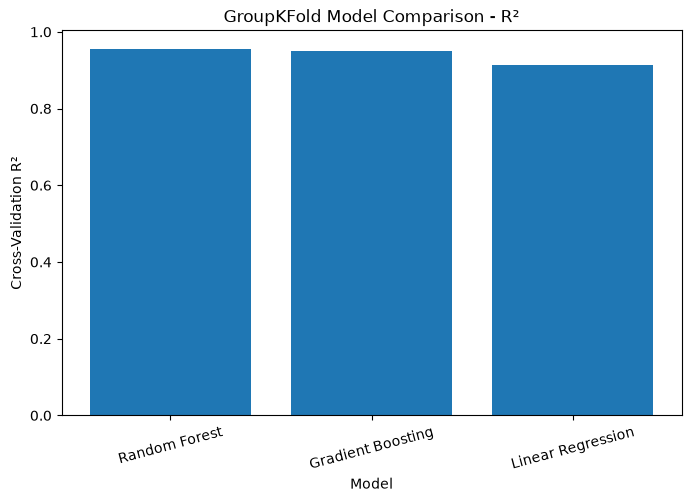

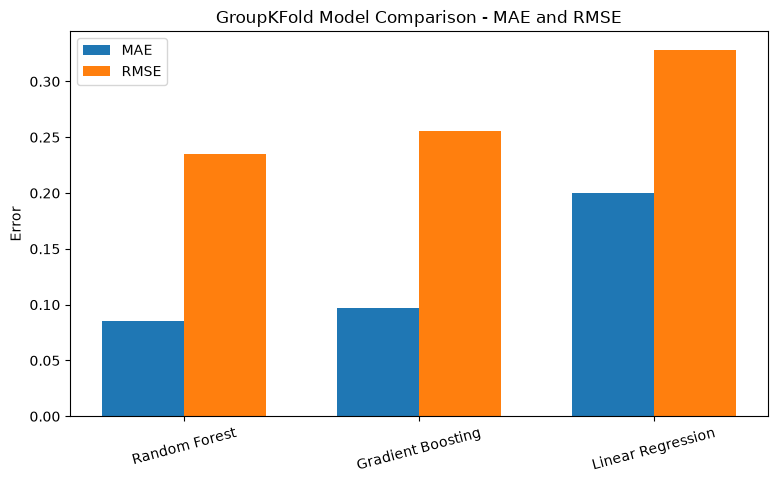

In [13]:
plt.figure(figsize=(8, 5))

plt.bar(
    cv_results["Model"],
    cv_results["CV R²"]
)

plt.xlabel("Model")
plt.ylabel("Cross-Validation R²")
plt.title("GroupKFold Model Comparison - R²")

plt.xticks(rotation=15)

plt.show()

x = np.arange(len(cv_results))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    cv_results["CV MAE"],
    width,
    label="MAE"
)

plt.bar(
    x + width / 2,
    cv_results["CV RMSE"],
    width,
    label="RMSE"
)

plt.xticks(
    x,
    cv_results["Model"],
    rotation=15
)

plt.ylabel("Error")
plt.title("GroupKFold Model Comparison - MAE and RMSE")
plt.legend()

plt.show()

## Select Best Model

เลือกโมเดลที่มีค่า `CV R²` สูงที่สุดจากผลการทำ GroupKFold Cross-Validation

การเลือกโมเดลจะทำจากผลของ Cross-Validation ก่อนที่จะนำโมเดลไปประเมินกับ Holdout Test Set


In [14]:
best_name = cv_results.iloc[0]["Model"]

print("Best model based on GroupKFold CV R²:" ,best_name)

Best model based on GroupKFold CV R²: Random Forest


### การแบ่งข้อมูลสำหรับ Training และ Testing
ใช้ GroupShuffleSplit แบ่งข้อมูลเป็น Training Data 80% และ Testing Data 20% โดยใช้ Group เพื่อป้องกันข้อมูลที่มี Feature Profile ซ้ำกันระหว่าง Training และ Testing และใช้ random_state = 42 เพื่อให้สามารถทำซ้ำผลการแบ่งข้อมูลได้ การแบ่งข้อมูลโดยใช้ Group ช่วยป้องกันไม่ให้ข้อมูลที่มี Feature Profile เดียวกัน ถูกแบ่งไปอยู่ทั้ง Training และ Testing ซึ่งอาจทำให้ผลการประเมินโมเดลสูงกว่าความเป็นจริง จากนั้นนำตำแหน่งของข้อมูลที่ได้จากการแบ่งมาใช้สร้าง X_train, X_test, y_train และ y_test โดย X_train และ y_train ใช้สำหรับฝึกโมเดล ส่วน X_test และ y_test ใช้สำหรับทดสอบโมเดลกับข้อมูลที่ไม่ได้ใช้ในการฝึก

In [15]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (312, 9)
Testing data: (62, 9)


## Train and Evaluate Models on Holdout Test

ฝึก Regression Model ทั้ง 3 โมเดลด้วย Training Set
และนำแต่ละโมเดลไปทำนายข้อมูลใน Holdout Test Set

จากนั้นประเมินผลด้วย

- Test R² เพื่อวัดความสามารถในการอธิบายความแปรปรวนของข้อมูลทดสอบ
- Test MAE เพื่อวัดค่าความคลาดเคลื่อนสัมบูรณ์เฉลี่ย
- Test RMSE เพื่อวัดค่าความคลาดเคลื่อนโดยให้น้ำหนักกับ Error ขนาดใหญ่มากขึ้น

ผลลัพธ์ของทั้ง 3 โมเดลจะถูกนำมาเปรียบเทียบกัน
เพื่อดูประสิทธิภาพของโมเดลบนข้อมูลที่ไม่เคยใช้ในการฝึก

In [16]:
holdout_rows = []
fitted_models = {}

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)

    fitted_models[name] = pipe

    holdout_rows.append({
        "Model": name,
        "Test R²": r2_score(y_test, pred),
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test RMSE": mean_squared_error(
            y_test,
            pred
        ) ** 0.5
    })

holdout_results = pd.DataFrame(holdout_rows)

holdout_results = holdout_results.sort_values(
    "Test R²",
    ascending=False
)

display(holdout_results)

,Model,Test R²,Test MAE,Test RMSE
1,Random Forest,0.939952,0.087312,0.246857
2,Gradient Boosting,0.929114,0.111178,0.268211
0,Linear Regression,0.900342,0.217130,0.318019


### Actual vs Predicted ของ Best Model

นำโมเดลที่เลือกจาก GroupKFold มาทำนายค่า `Quality of Sleep`
บน Holdout Test Set เปรียบเทียบค่าจริง (Actual) กับค่าที่โมเดลทำนาย (Predicted) ถ้าจุดอยู่ใกล้เส้น diagonal มาก แสดงว่าค่าที่ทำนายมีความใกล้เคียงกับค่าจริงมากขึ้น

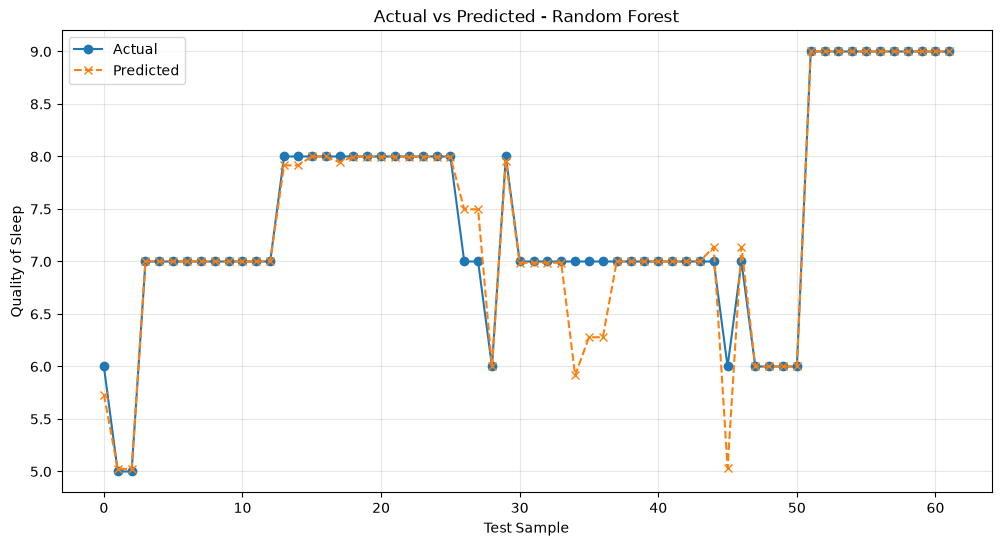

,Actual,Predicted,Error
0,6,5.732907,0.267093
1,5,5.024440,-0.024440
2,5,5.024440,-0.024440
3,7,7.000000,0.000000
4,7,7.000000,0.000000
5,7,7.000000,0.000000
6,7,7.000000,0.000000
7,7,7.000000,0.000000
8,7,7.000000,0.000000
9,7,7.000000,0.000000


In [17]:
best_model = fitted_models[best_name]

best_pred = best_model.predict(X_test)

plt.figure(figsize=(12, 6))

x = np.arange(len(y_test))

plt.plot(
    x,
    y_test.values,
    "o-",
    label="Actual"
)

plt.plot(
    x,
    best_pred,
    "x--",
    label="Predicted"
)

plt.xlabel("Test Sample")
plt.ylabel("Quality of Sleep")

plt.title(
    f"Actual vs Predicted - {best_name}"
)

plt.legend()
plt.grid(alpha=0.3)

plt.show()

prediction_comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": best_pred
})

prediction_comparison["Error"] = (
    prediction_comparison["Actual"]
    - prediction_comparison["Predicted"]
)

display(
    prediction_comparison.head(15)
)

In [18]:
import joblib

joblib.dump(
    best_model,
    "sleep_quality_model_fn.pkl"
)

print("Model saved successfully.")
print("Saved model:", best_name)

Model saved successfully.
Saved model: Random Forest


## Feature Importance

วิเคราะห์ว่า Feature ใดมีความสำคัญต่อการทำนายของโมเดลมากที่สุด

ดึง Feature Names หลังจากผ่าน Preprocessing และตรวจสอบว่าโมเดล
มีค่า `feature_importances_` หรือ `coef_` ที่สามารถใช้ประเมินความสำคัญของ Feature ได้หรือไม่

จากนั้นเรียงลำดับ Feature ตาม Importance และแสดง
Top 15 Features รวมถึงสร้างกราฟ Top 10 Features

Feature Importance ใช้เพื่ออธิบายว่า Feature ใดมีบทบาทต่อการทำนายของโมเดลมากกว่า
แต่ไม่ได้หมายความว่า Feature นั้นเป็นสาเหตุโดยตรงของ Quality of Sleep

,Feature,Importance
1,numeric__Sleep Duration,0.804605
3,numeric__Stress Level,0.112783
9,categorical__Occupation_Doctor,0.028865
4,numeric__Heart Rate,0.020940
5,numeric__Daily Steps,0.012604
0,numeric__Age,0.009478
8,categorical__Occupation_Accountant,0.006166
22,categorical__BMI Category_Overweight,0.000905
2,numeric__Physical Activity Level,0.000720
21,categorical__BMI Category_Obese,0.000690


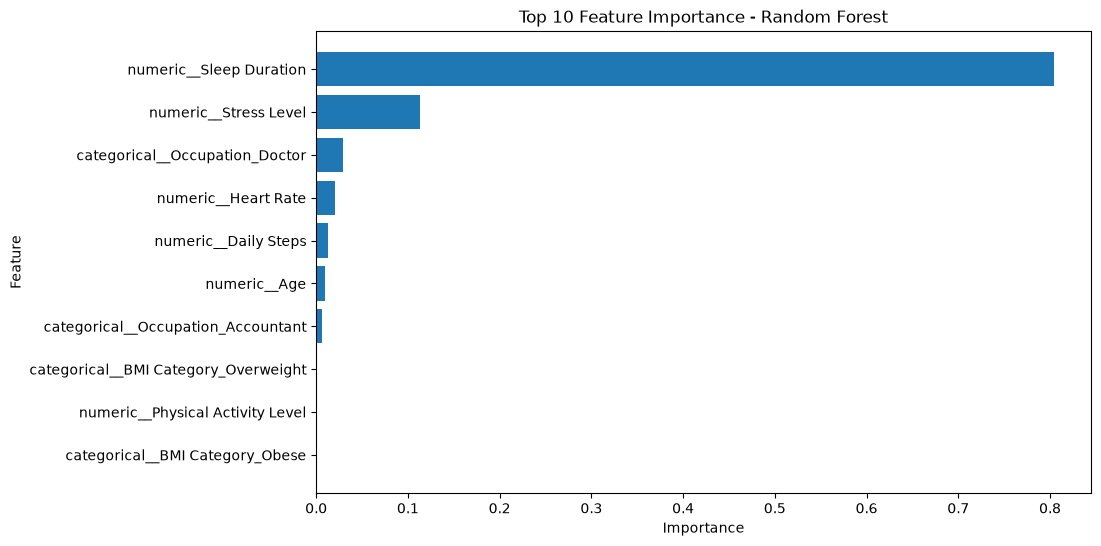

In [19]:
estimator = best_model.named_steps["model"]

prep = best_model.named_steps["preprocessor"]

feature_names = prep.get_feature_names_out()

if hasattr(estimator, "feature_importances_"):

    importance = estimator.feature_importances_

elif hasattr(estimator, "coef_"):

    importance = np.abs(estimator.coef_)

else:

    importance = None

if importance is not None:

    feature_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })

    feature_importance = feature_importance.sort_values(
        "Importance",
        ascending=False
    )

    display(
        feature_importance.head(15)
    )

else:

    print(
        "This model does not provide feature importance."
    )

if importance is not None:

    top_features = feature_importance.head(10)

    plt.figure(figsize=(10, 6))

    plt.barh(
        top_features["Feature"][::-1],
        top_features["Importance"][::-1]
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.title(
        f"Top 10 Feature Importance - {best_name}"
    )

    plt.show()